In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Install/Update Ultralytics and supporting libraries
!pip install ultralytics -U -q
!pip install opencv-python-headless tqdm -q

# Verify Hardware
import ultralytics
ultralytics.checks()

Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.5/112.6 GB disk)


In [ ]:
import os, json, glob, cv2, yaml, shutil
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

class Config:
    DRIVE_ROOT = '/content/drive/MyDrive/ Car DataSet FYP/CarDamageProject/car-parts-segmentation-1'
    LOCAL_ROOT = '/content/car_parts_local'
    DRIVE_SAVE_PATH = '/content/drive/MyDrive/ Car DataSet FYP/Training'

    SPLITS = ['train', 'valid', 'test']

    # EXACT list from JSON (ID 0 to 21)
    CLASSES = [
        'car-parts', 'Back-bumper', 'Back-door', 'Back-wheel', 'Back-window',
        'Back-windshield', 'Fender', 'Front-bumper', 'Front-door', 'Front-wheel',
        'Front-window', 'Grille', 'Headlight', 'Hood', 'License-plate',
        'Mirror', 'Quarter-panel', 'Rocker-panel', 'Roof', 'Tail-light',
        'Trunk', 'Windshield'
    ]

    MIN_SEGMENT_AREA = 100

conf = Config()

In [ ]:
def process_dataset():
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    # Wipe temporary storage to prevent label duplication if cell is re-run
    if os.path.exists(conf.LOCAL_ROOT):
        shutil.rmtree(conf.LOCAL_ROOT)
        print("Temporary storage cleared.")

    for split in conf.SPLITS:
        src_path = os.path.join(conf.DRIVE_ROOT, split)
        dest_img_dir = os.path.join(conf.LOCAL_ROOT, split, 'images')
        dest_lbl_dir = os.path.join(conf.LOCAL_ROOT, split, 'labels')
        os.makedirs(dest_img_dir, exist_ok=True)
        os.makedirs(dest_lbl_dir, exist_ok=True)

        # Load COCO JSON
        json_files = glob.glob(os.path.join(src_path, "*.json"))
        if not json_files:
            print(f"No JSON in {split}. Skipping...")
            continue

        with open(json_files[0], 'r') as f:
            coco_data = json.load(f)

        img_map = {img['id']: img for img in coco_data['images']}
        cat_map = {cat['id']: i for i, cat in enumerate(coco_data['categories'])}

        # Process Annotations
        for ann in tqdm(coco_data['annotations'], desc=f"Processing {split}"):
            img_info = img_map.get(ann['image_id'])
            if not img_info: continue

            filename = img_info['file_name']
            src_img_path = os.path.join(src_path, filename)
            dest_img_path = os.path.join(dest_img_dir, filename)

            # Process Image once
            if not os.path.exists(dest_img_path):
                img = cv2.imread(src_img_path)
                if img is None: continue # Skip corrupt

                # CLAHE Enhancement
                lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
                l, a, b = cv2.split(lab)
                enhanced = cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)
                cv2.imwrite(dest_img_path, enhanced)

            # Create YOLO Label
            w, h = img_info['width'], img_info['height']
            label_file = os.path.join(dest_lbl_dir, os.path.splitext(filename)[0] + ".txt")

            with open(label_file, 'a') as f:
                for seg in ann['segmentation']:
                    if len(seg) < 6: continue
                    poly = np.array(seg).reshape(-1, 2)
                    if cv2.contourArea(poly.astype(np.float32)) < conf.MIN_SEGMENT_AREA:
                        continue

                    norm = [seg[i]/w if i%2==0 else seg[i]/h for i in range(len(seg))]
                    f.write(f"{cat_map[ann['category_id']]} " + " ".join([f"{c:.6f}" for c in norm]) + "\n")

    # Generate data.yaml
    yaml_dict = {
        'path': conf.LOCAL_ROOT,
        'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
        'names': {i: name for i, name in enumerate(conf.CLASSES)}
    }
    with open(os.path.join(conf.LOCAL_ROOT, 'data.yaml'), 'w') as f:
        yaml.dump(yaml_dict, f)

    print(f"Preprocessing complete at {conf.LOCAL_ROOT}")

process_dataset()

Processing test: 100%|██████████| 4458/4458 [00:12<00:00, 360.39it/s]


Preprocessing complete at /content/car_parts_local


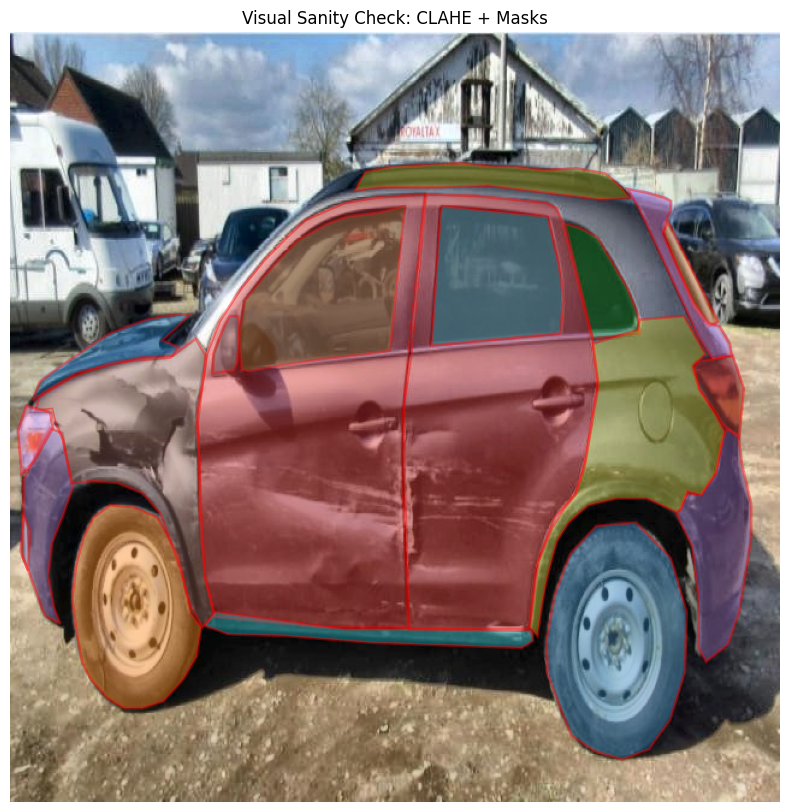

In [ ]:
def visualize_sample():
    # Pick a random image from local training set
    img_list = glob.glob(os.path.join(conf.LOCAL_ROOT, 'train/images/*.jpg'))
    img_path = img_list[np.random.randint(0, len(img_list))]
    lbl_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    plt.figure(figsize=(10, 10))
    plt.imshow(img)

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.split()
                coords = np.array([float(x) for x in parts[1:]]).reshape(-1, 2)
                plt.fill(coords[:, 0] * w, coords[:, 1] * h, alpha=0.4, edgecolor='red', linewidth=2)

    plt.title("Visual Sanity Check: CLAHE + Masks")
    plt.axis('off')
    plt.show()

visualize_sample()

In [ ]:
from ultralytics import YOLO

# Load YOLOv11 Segmentation Model
model = YOLO('yolo11n-seg.pt')

# Start Training
model.train(
    data=os.path.join(conf.LOCAL_ROOT, 'data.yaml'),
    imgsz=1024,
    epochs=100,
    batch=8,
    patience=25,
    device=0,
    project=conf.DRIVE_SAVE_PATH,
    name='yolov11_car_parts_final',
    exist_ok=True,
    save=True,
    augment=True
)

In [ ]:
!pip uninstall ultralytics -y
!pip install ultralytics -U

Found existing installation: ultralytics 8.4.21
Uninstalling ultralytics-8.4.21:
  Successfully uninstalled ultralytics-8.4.21
  Using cached ultralytics-8.4.21-py3-none-any.whl.metadata (39 kB)
Using cached ultralytics-8.4.21-py3-none-any.whl (1.2 MB)


In [ ]:
from ultralytics import YOLO
import os

# --- PATHS ---
LAST_WEIGHTS = '/content/drive/MyDrive/ Car DataSet FYP/Training/yolov11_car_parts_final/weights/last.pt'
YAML_PATH = '/content/car_parts_local/data.yaml'

def run_training():
    # Check if a previous run exists to resume
    if os.path.exists(LAST_WEIGHTS):
        print("Resuming training from last checkpoint...")
        model = YOLO(LAST_WEIGHTS)
        model.train(resume=True)
    else:
        print("Starting fresh training...")
        model = YOLO('yolo11n-seg.pt')
        model.train(
            data=YAML_PATH,
            imgsz=1024,
            epochs=100,
            batch=8,
            patience=25,
            device=0, # Use GPU
            project='/content/drive/MyDrive/ Car DataSet FYP/Training',
            name='yolov11_car_parts_final',
            save_period=5, # Safety: Save every 5 epochs
            exist_ok=True
        )

run_training()

In [ ]:
# EVALUATION
from ultralytics import YOLO

print("Running final evaluation on Validation Set...")

# Load weights
best_model = YOLO('/content/drive/MyDrive/ Car DataSet FYP/Training/yolov11_car_parts_final/weights/best.pt')

# Run validation
metrics = best_model.val()

print("\n FINAL METRICS SUMMARY")
# Mask metrics (M) are for segmentation accuracy
print(f"Mean Precision: {metrics.seg.mp:.4f}")
print(f"Mean Recall: {metrics.seg.mr:.4f}")
print(f"Overall Mask mAP50: {metrics.seg.map50:.4f}")
print(f"Overall Mask mAP50-95: {metrics.seg.map:.4f}")

# Class-wise performance check
print("\n PERFORMANCE PER PART (mAP50)")
# Hum metrics.seg.maps use karte hain har class ka score nikalne ke liye
maps = metrics.seg.maps
for i, name in enumerate(best_model.names.values()):
    score = maps[i]
    print(f"Part: {name:20} | Mask mAP50: {score:.4f}")

Running final evaluation on Validation Set...
Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,838,858 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2217.9±453.1 MB/s, size: 122.8 KB)
val: Scanning /content/car_parts_local/valid/labels... 560 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 560/560 1.1Kit/s 0.5s
val: New cache created: /content/car_parts_local/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 1.3it/s 27.5s
                   all        560       8581      0.935      0.903      0.947      0.798      0.939      0.907      0.945      0.748
           Back-bumper        241        242      0.961      0.864      0.951       0.82      0.966      0.868      0.943      0.801
             Back-door        398        407       0.97     

Upload a new car image to test segmentation:


Saving car1.jpg to car1.jpg

image 1/1 /content/car1.jpg: 704x1024 1 Back-bumper, 1 Back-wheel, 1 Fender, 1 Front-door, 1 Front-wheel, 1 Mirror, 1 Quarter-panel, 1 Rocker-panel, 1 Tail-light, 92.2ms
Speed: 10.7ms preprocess, 92.2ms inference, 9.6ms postprocess per image at shape (1, 3, 704, 1024)
Results saved to /content/runs/segment/predict

Results for: car1.jpg


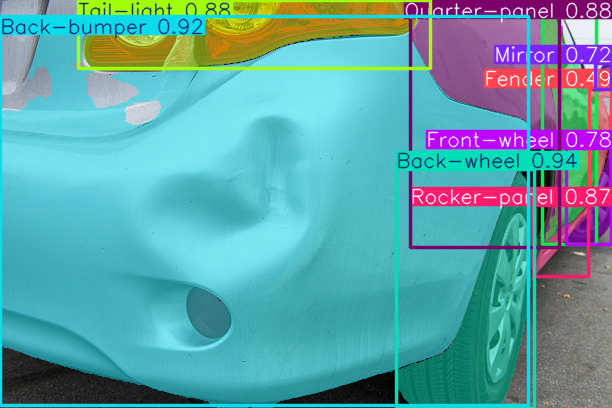

In [ ]:
# VISUAL TESTING
import cv2
from google.colab.patches import cv2_imshow
from google.colab import files

print("Upload a new car image to test segmentation:")
uploaded = files.upload()

for filename in uploaded.keys():
    # Run prediction with a slightly higher confidence to avoid noise
    results = best_model.predict(source=filename, conf=0.40, save=True)

    # Plotting the results
    res_plotted = results[0].plot()

    print(f"\nResults for: {filename}")
    cv2_imshow(res_plotted)